# Chapter 11

Python version of the R code for Chapter 11 of *In All Likelihood* (Pawitan, 2001).

Random numbers are generated with numpy, so simulated results will not
match the R output exactly. R's `survreg()` has no direct statsmodels
equivalent, so Example 11.6 maximises the same censored log-likelihood
directly; `coxph()` and `survfit()` are replaced by statsmodels' `PHReg`
and `SurvfuncRight`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats, optimize
from statsmodels.graphics.tsaplots import plot_acf

from helpers import scan, ar_sim, cut, table, num_hessian

## Example 11.1 (`EX11-1.R`)

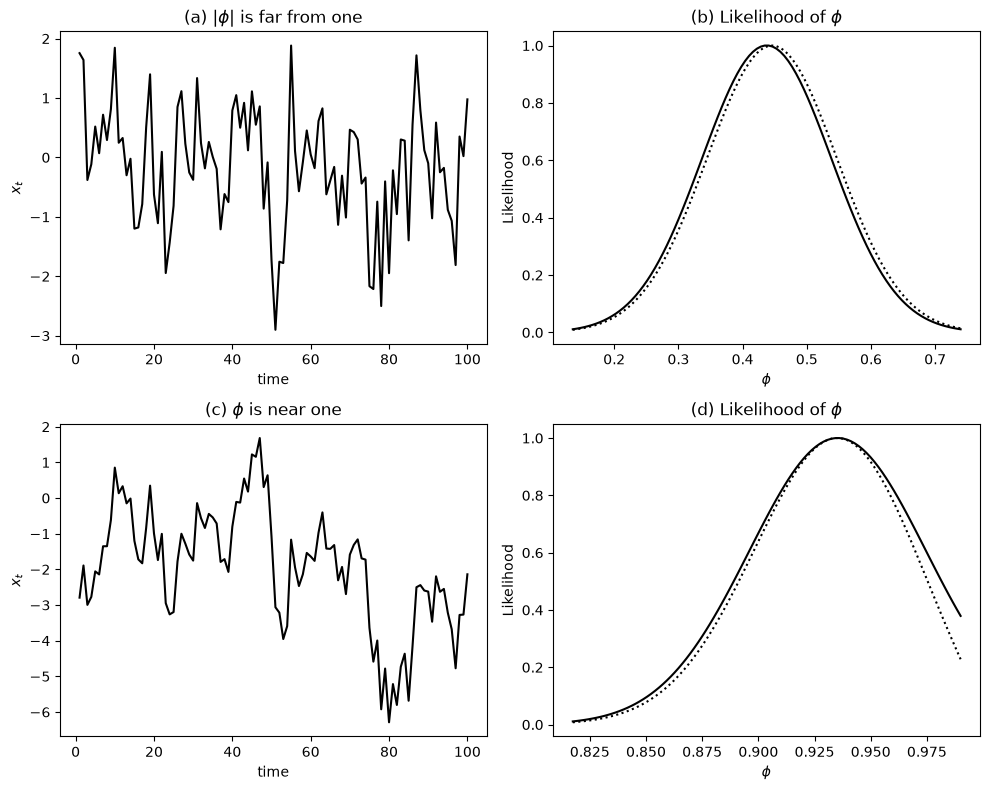

In [2]:
def plot_ar_likelihood(x, ax):
    n = len(x)
    xt = x[1:]
    xt1 = x[:-1]

    phihat = np.sum(xt * xt1) / np.sum(xt1 ** 2)
    se = 1 / np.sqrt(np.sum(xt1 ** 2))
    phi = np.linspace(phihat - 3 * se, min(phihat + 3 * se, .99), 100)

    # conditional likelihood, given x[0]
    ll2 = -1 / 2 * (np.sum(xt ** 2) + phi ** 2 * np.sum(xt1 ** 2) - 2 * phi * np.sum(xt * xt1))
    ll2 = ll2 - ll2.max()
    l2 = np.exp(ll2)
    ax.plot(phi, l2, "k-")

    # full likelihood
    ll1 = 1 / 2 * np.log(1 - phi ** 2) - 1 / 2 * (1 - phi ** 2) * x[0] ** 2
    ll = ll1 + ll2
    ll = ll - ll.max()
    lik = np.exp(ll)
    ax.plot(phi, lik, "k:", lw=1.5)
    ax.set_xlabel(r"$\phi$")
    ax.set_ylabel("Likelihood")


fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.ravel()

rng = np.random.default_rng(7)
n = 100
x = ar_sim(n, 0.5, rng=rng)  # simulate AR(1) data

ax = axes[0]
ax.plot(np.arange(1, n + 1), x, "k-")
ax.set_xlabel("time")
ax.set_ylabel(r"$x_t$")
ax.set_title(r"(a) |$\phi$| is far from one")

plot_ar_likelihood(x, axes[1])
axes[1].set_title(r"(b) Likelihood of $\phi$")

# ...... second example
rng = np.random.default_rng(7)
n = 100
x = ar_sim(n, 0.95, rng=rng)  # simulated AR(1) data
ax = axes[2]
ax.plot(np.arange(1, n + 1), x, "k-")
ax.set_xlabel("time")
ax.set_ylabel(r"$x_t$")
ax.set_title(r"(c) $\phi$ is near one")

plot_ar_likelihood(x, axes[3])
axes[3].set_title(r"(d) Likelihood of $\phi$")

fig.tight_layout()
plt.show()

## Example 11.2 (`EX11-2.R`)

col_0  0.0  1.0
row_0          
0.0     82    8
1.0      8   11


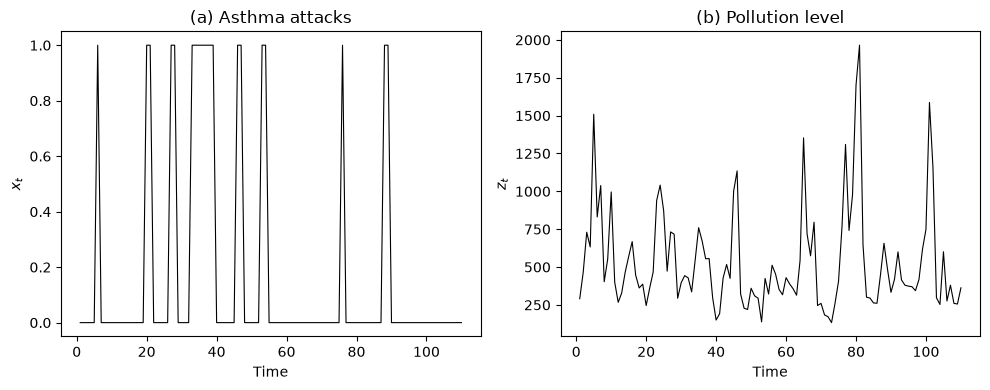

In [3]:
y = scan("asthma.dat")
n = len(y)
print(pd.crosstab(y[:-1], y[1:]))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ax = axes[0]
ax.plot(np.arange(1, n + 1), y, "k-", lw=0.8)
ax.set_xlabel("Time")
ax.set_ylabel(r"$x_t$")
ax.set_title("(a) Asthma attacks")

# ..........................    pollution data:

x = scan("pollute.dat").reshape(-1, 5)
x = x[:, 1]  # smoke concentration in ppm
ax = axes[1]
ax.plot(np.arange(1, len(x) + 1), x, "k-", lw=0.8)
ax.set_xlabel("Time")
ax.set_ylabel(r"$z_t$")
ax.set_title("(b) Pollution level")
fig.tight_layout()
plt.show()

## Example 11.3 (`EX11-3.R`)

In [4]:
x = scan("ulcer.dat").reshape(-1, 12)
x1 = x[:, 1:6]
x2 = x[:29, 7:12]

# Change from begin --> end
a1 = (x1[:, 0] - x1[:, 4]) > 0  # true=better
a2 = (x2[:, 0] - x2[:, 4]) > 0
print(pd.Series(a1).value_counts().sort_index())
print(pd.Series(a2).value_counts().sort_index())


def transitions(x):
    """Count the +1, 0 and -1 transitions between successive visits."""
    X = np.column_stack([x[:, 0:4].ravel(order="F"), x[:, 1:5].ravel(order="F")])
    t = pd.crosstab(X[:, 0], X[:, 1]).to_numpy()
    print("Other +1 =", t[1, 2] + t[2, 3] + t[3, 4] + t[4, 5])
    print("Other 0 =", t[1, 1] + t[2, 2] + t[3, 3] + t[4, 4])
    print("Other -1 =", t[1, 0] + t[2, 1] + t[3, 2] + t[4, 3])


# pairing the observations
transitions(x1)
transitions(x2)

False    14
True     16
Name: count, dtype: int64
False     7
True     22
Name: count, dtype: int64
Other +1 = 3
Other 0 = 84
Other -1 = 19
Other +1 = 2
Other 0 = 63
Other -1 = 30


## Example 11.5 (`EX11-5.R`)

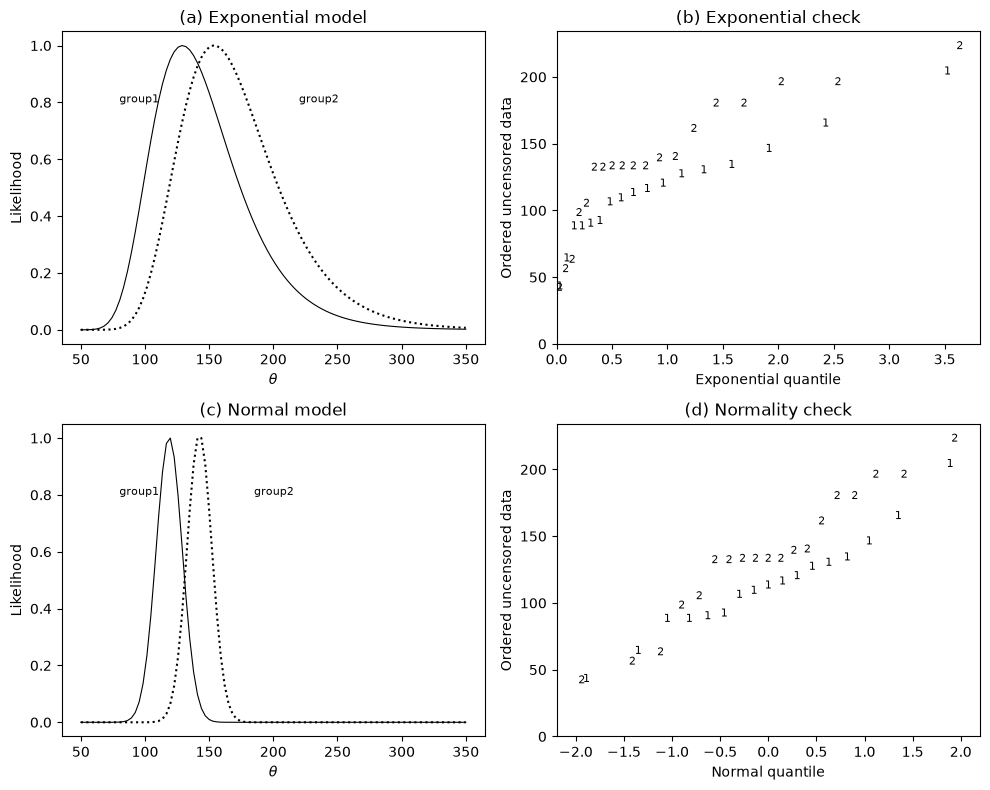

In [5]:
group, surv, status = scan("rat.dat", skip=1).reshape(-1, 3).T
t1 = 100
surv = surv - t1
n1 = np.sum(group == 1)
n2 = np.sum(group == 2)
c1 = np.sum((group == 1) & (status == 0))
c2 = np.sum((group == 2) & (status == 0))
x1 = surv[group == 1]
x2 = surv[group == 2]

# exponential likelihood

theta = np.linspace(50, 350, 100)

loglik1 = -(n1 - c1) * np.log(theta) - x1.sum() / theta
lik1 = np.exp(loglik1 - loglik1.max())

loglik2 = -(n2 - c2) * np.log(theta) - x2.sum() / theta
lik2 = np.exp(loglik2 - loglik2.max())

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.ravel()

ax = axes[0]
ax.plot(theta, lik1, "k-", lw=0.8)
ax.plot(theta, lik2, "k:", lw=1.5)
ax.text(220, .8, "group2", fontsize=8)
ax.text(80, .8, "group1", fontsize=8)
ax.set_xlabel(r"$\theta$")
ax.set_ylabel("Likelihood")
ax.set_title("(a) Exponential model")


def labelled_points(ax, q, data, label):
    for qi, di in zip(np.sort(q), np.sort(data)):
        ax.text(qi, di, label, fontsize=8, ha="center", va="center")


ax = axes[1]
a = -np.log(1 / 34 + np.arange(17) / 17)
labelled_points(ax, a, x1[:17], "1")
a2 = -np.log(1 / 38 + np.arange(19) / 19)
labelled_points(ax, a2, x2[:19], "2")
ax.set_xlim(0, max(a.max(), a2.max()) * 1.05)
ax.set_ylim(0, max(x1[:17].max(), x2[:19].max()) * 1.05)
ax.set_xlabel("Exponential quantile")
ax.set_ylabel("Ordered uncensored data")
ax.set_title("(b) Exponential check")

# using normal model

sig2 = (16 * np.var(x1[:17], ddof=1) + 18 * np.var(x2[:19], ddof=1)) / 34
sig = np.sqrt(sig2)

loglik1 = np.array([-np.sum((x1[:17] - t) ** 2) / 2 / sig2 for t in theta])
lik1 = np.exp(loglik1 - loglik1.max())
for i in [17, 18]:  # censored
    lik1 = lik1 * (1 - stats.norm.cdf(x1[i], theta, sig))
lik1 = lik1 / lik1.max()

loglik2 = np.array([-np.sum((x2[:19] - t) ** 2) / 2 / sig2 for t in theta])
lik2 = np.exp(loglik2 - loglik2.max())
for i in [19, 20]:  # censored
    lik2 = lik2 * (1 - stats.norm.cdf(x2[i], theta, sig))
lik2 = lik2 / lik2.max()

ax = axes[2]
ax.plot(theta, lik1, "k-", lw=0.8)
ax.plot(theta, lik2, "k:", lw=1.5)
ax.text(185, .8, "group2", fontsize=8)
ax.text(80, .8, "group1", fontsize=8)
ax.set_xlabel(r"$\theta$")
ax.set_ylabel("Likelihood")
ax.set_title("(c) Normal model")

ax = axes[3]
a = stats.norm.ppf(1 / 34 + np.arange(17) / 17)
labelled_points(ax, a, x1[:17], "1")
a2 = stats.norm.ppf(1 / 38 + np.arange(19) / 19)
labelled_points(ax, a2, x2[:19], "2")
ax.set_xlim(-2.2, 2.2)
ax.set_ylim(0, max(x1[:17].max(), x2[:19].max()) * 1.05)
ax.set_xlabel("Normal quantile")
ax.set_ylabel("Ordered uncensored data")
ax.set_title("(d) Normality check")

fig.tight_layout()
plt.show()

## `EX11-6.R`

This script is headed "Example 10.6". It fits exponential and Weibull
regression models (R's `survreg()`) to the rat data. Here the same
log-likelihood is maximised directly: log(T) = b0 + b1*group2 + scale*W,
where W has the standard extreme-value distribution and scale=1 for the
exponential model.

In [6]:
group, surv, status = scan("rat.dat", skip=1).reshape(-1, 3).T
t1 = 100
surv = surv - t1
X = np.column_stack([np.ones(len(surv)), group == 2])


def survreg_loglik(p, weibull):
    beta = p[:2]
    scale = np.exp(p[2]) if weibull else 1.0
    z = (np.log(surv) - X @ beta) / scale
    # density on the time scale for deaths, survivor function for censored
    logf = z - np.exp(z) - np.log(scale) - np.log(surv)
    logS = -np.exp(z)
    return np.sum(np.where(status == 1, logf, logS))


def survreg(weibull):
    p0 = [np.log(surv.mean()), 0, 0]
    k = 3 if weibull else 2

    def nll(p):
        return -survreg_loglik(np.append(p, 0)[:3], weibull)

    res = optimize.minimize(nll, p0[:k], method="BFGS")
    se = np.sqrt(np.diag(np.linalg.inv(num_hessian(nll, res.x))))
    names = ["(Intercept)", "factor(group)2", "Log(scale)"][:k]
    print(pd.DataFrame({"Value": res.x, "Std. Error": se, "z": res.x / se}, index=names))
    if weibull:
        print("Scale=", np.exp(res.x[2]))
    print("Loglik(model)=", -res.fun)
    return -res.fun


print("Exponential:")
loglik1 = survreg(weibull=False)
print()
print("Weibull:")
loglik2 = survreg(weibull=True)

# Weibull vs exponential: LRT=44.8
print()
print("Weibull vs Exponential: LRT= ", 2 * (loglik2 - loglik1))

Exponential:
                   Value  Std. Error          z
(Intercept)     4.860724    0.242536  20.041280
factor(group)2  0.175203    0.333849   0.524796
Loglik(model)= -214.3149166176533

Weibull:
                   Value  Std. Error          z
(Intercept)     4.873434    0.079017  61.675996
factor(group)2  0.212990    0.107811   1.975587
Log(scale)     -1.130769    0.129996  -8.698526
Scale= 0.32278482803947917
Loglik(model)= -191.93354347198235

Weibull vs Exponential: LRT=  44.7627462913419


## Example 11.8 (`EX11-8.R`)

In [7]:
group, surv, status = scan("rat.dat", skip=1).reshape(-1, 3).T
t1 = 100
surv = surv - t1

a = sm.PHReg(surv, group[:, None], status=status, ties="efron").fit(start_params=[-.2])
print(a.summary(xname=["group"]))

                      Results: PHReg
Model:                     PH Reg      Sample size:      40
Dependent variable:        y           Num. events:      36
Ties:                      Efron                           
-----------------------------------------------------------
       log HR log HR SE   HR      t    P>|t|  [0.025 0.975]
-----------------------------------------------------------
group -0.5686    0.3472 0.5663 -1.6378 0.1015 0.2868 1.1184
Confidence intervals are for the hazard ratios


## Figure 11.4 (`FIG11-4.R`)

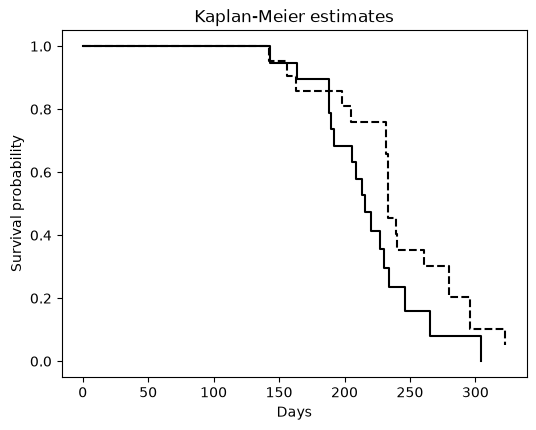

In [8]:
group, surv, status = scan("rat.dat", skip=1).reshape(-1, 3).T

fig, ax = plt.subplots(figsize=(6, 4.5))
for g, ls in [(1, "-"), (2, "--")]:
    est = sm.SurvfuncRight(surv[group == g], status[group == g])
    t = np.concatenate([[0], est.surv_times])
    s = np.concatenate([[1], est.surv_prob])
    ax.step(t, s, where="post", color="k", ls=ls)
ax.set_xlabel("Days")
ax.set_ylabel("Survival probability")
ax.set_title("Kaplan-Meier estimates")
plt.show()

## Example 11.9 (`EX11-9.R`)

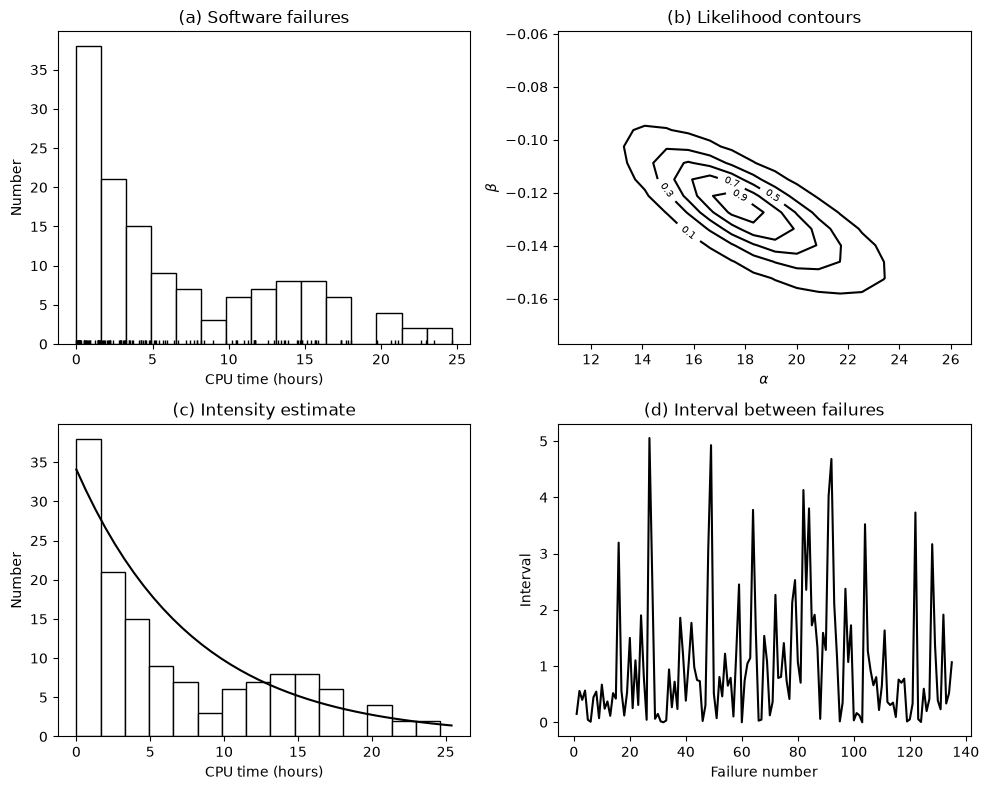

In [9]:
x = scan("software.dat")
tt = 25.4
x = x / 3600
n = len(x)

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.ravel()

ax = axes[0]
ax.hist(x, bins=15, color="w", edgecolor="k")
ax.plot(x, np.zeros(n), "k|", ms=6)
ax.set_xlabel("CPU time (hours)")
ax.set_ylabel("Number")
ax.set_title("(a) Software failures")

sumx = x.sum()


def fun1(alpha, beta):
    return -alpha / beta * (np.exp(beta * tt) - 1) + n * np.log(alpha) + beta * sumx


aa = np.linspace(2 * n, 5 * n, 20) / tt
bb = np.linspace(-4.5, -1.5, 20) / tt

loglik = fun1(aa[:, None], bb[None, :])
lik = np.exp(loglik - loglik.max())
ax = axes[1]
cs = ax.contour(aa, bb, lik.T, levels=np.arange(.1, 1, .2), colors="k")
ax.clabel(cs, fontsize=7)
ax.set_xlabel(r"$\alpha$")
ax.set_ylabel(r"$\beta$")
ax.set_title("(b) Likelihood contours")


# minimization
def fn(p):
    alpha, beta = p
    return alpha / beta * (np.exp(beta * tt) - 1) - n * np.log(alpha) - beta * sumx


xmin = optimize.minimize(fn, [20, -.14], method="Nelder-Mead")
a, b = xmin.x

ax = axes[2]
ax.hist(x, bins=15, color="w", edgecolor="k")
xx = np.linspace(0, tt, 40)
xy = a * np.exp(b * xx)
xy = xy / xy.sum() / (xx[1] - xx[0]) * n * 2
ax.plot(xx, xy, "k-")
ax.set_xlabel("CPU time (hours)")
ax.set_ylabel("Number")
ax.set_title("(c) Intensity estimate")

# checking the Poisson assumption:
# using exponential trend result:
y = x[1:] - x[:-1]
lam = a * np.exp(b * x)
yy = lam[:-1] * y
ax = axes[3]
ax.plot(np.arange(1, len(yy) + 1), yy, "k-")
ax.set_xlabel("Failure number")
ax.set_ylabel("Interval")
ax.set_title("(d) Interval between failures")

fig.tight_layout()
plt.show()

## Figure 11.6 (`FIG11-6.R`)

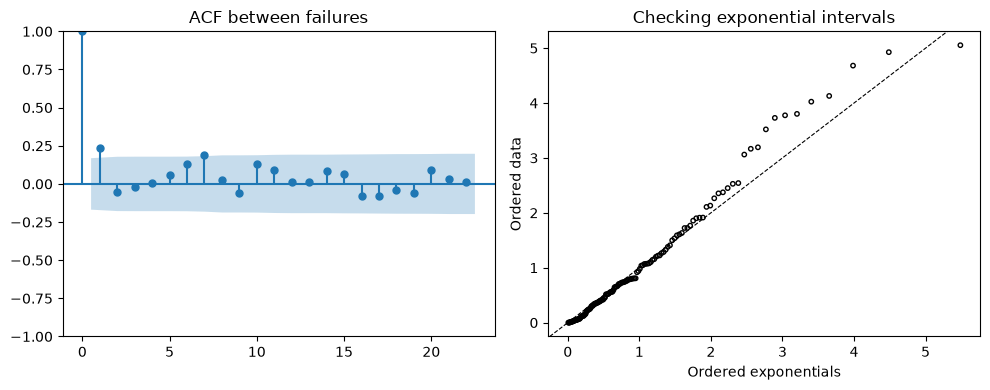

In [10]:
x = scan("software.dat")
tt = 25.4
x = x / 3600
n = len(x)
sumx = x.sum()  # as in Example 11.9


# minimization
def fn(p):
    alpha, beta = p
    return alpha / beta * (np.exp(beta * tt) - 1) - n * np.log(alpha) - beta * sumx


xmin = optimize.minimize(fn, [20, -.14], method="Nelder-Mead")
a, b = xmin.x

# checking the Poisson assumption:
y = np.diff(x)
lam = a * np.exp(b * x)
yy = lam[:-1] * y

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
plot_acf(yy, ax=axes[0], title="ACF between failures")

aa = np.cumsum(1 / np.arange(len(yy), 0, -1))
ax = axes[1]
ax.scatter(np.sort(aa), np.sort(yy), s=10, facecolors="none", edgecolors="k")
ax.axline((0, 0), slope=1, color="k", ls="--", lw=0.8)
ax.set_xlabel("Ordered exponentials")
ax.set_ylabel("Ordered data")
ax.set_title("Checking exponential intervals")
fig.tight_layout()
plt.show()

## Example 11.11 (`EX11-11.R`)

In [11]:
# reading data:
m1 = 10  # active
m2 = 12  # placebo
T12 = scan("epi.dat", skip=2, nlines=1)  # follow-up times
T1 = T12[:10]
T2 = T12[10:22]
n12 = scan("epi.dat", skip=4, nlines=1)  # number of events
n1 = n12[:10]
n2 = n12[10:22]
t1 = scan("epi.dat", skip=7, nlines=2)   # event times, active
t2 = scan("epi.dat", skip=10)            # event times, placebo

# cutting into intervals
cutp = np.arange(1, 16) - .01
d1 = table(cut(T1, cutp - .01), len(cutp) - 1)
risk1 = np.concatenate([[m1], m1 - np.cumsum(d1)])
d2 = table(cut(T2, cutp - .1), len(cutp) - 1)
risk2 = np.concatenate([[m2], m2 - np.cumsum(d2)])

breaks = np.concatenate([[-.1], cutp])
a1 = table(cut(t1, breaks), len(breaks) - 1)
a2 = table(cut(t2, breaks), len(breaks) - 1)

# data: ...............................Table 11.2
a = np.vstack([np.column_stack([np.arange(1, 15), np.ones(14), np.arange(0, 14), risk1[:14], a1[:14]]),
               np.column_stack([np.arange(15, 30), np.zeros(15), np.arange(0, 15), risk2, a2])])
print(pd.DataFrame(a, columns=["", "treat", "week", "risk", "events"]).astype(int).to_string(index=False))

# report:
a = np.vstack([np.column_stack([np.arange(0, 15), np.ones(15), risk1, a1]),
               np.column_stack([np.arange(0, 15), np.zeros(15), risk2, a2])])
a = np.delete(a, 14, axis=0)  # remove interval with none at risk

xdat = pd.DataFrame({"week": a[:, 0].astype(int), "treat": a[:, 1], "risk": a[:, 2], "y": a[:, 3]})

xreg = smf.glm("y ~ treat + C(week)", data=xdat, offset=np.log(xdat["risk"]),
               family=sm.families.Poisson()).fit()

coefs = pd.DataFrame({"Estimate": xreg.params, "Std. Error": xreg.bse})
coefs = pd.concat([coefs.loc[["Intercept", "treat"]], coefs.drop(["Intercept", "treat"])])
print(coefs.round(3))  # Table 11.3

    treat  week  risk  events
 1      1     0    10       4
 2      1     1    10       2
 3      1     2    10       4
 4      1     3    10       7
 5      1     4    10       1
 6      1     5     9       1
 7      1     6     9       3
 8      1     7     8       3
 9      1     8     6       0
10      1     9     6       0
11      1    10     4       1
12      1    11     3       0
13      1    12     1       2
14      1    13     1       1
15      0     0    12       9
16      0     1    12      11
17      0     2    12       7
18      0     3    12       5
19      0     4    10       4
20      0     5    10      12
21      0     6     9       6
22      0     7     7       5
23      0     8     6       5
24      0     9     5       2
25      0    10     5       2
26      0    11     2       1
27      0    12     2       1
28      0    13     2       0
29      0    14     2       1
               Estimate  Std. Error
Intercept        -0.247       0.284
treat            -0.767     

## Figure 11.8 (`FIG11-8.R`)

y_a and y_p =  29.0 71.0
Sum T_i =  97.0 109.0
                 Generalized Linear Model Regression Results                  
Dep. Variable:                      y   No. Observations:                   22
Model:                            GLM   Df Residuals:                       20
Model Family:                 Poisson   Df Model:                            1
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -43.600
Date:                Sat, 10 Oct 2026   Deviance:                       16.257
Time:                        17:57:20   Pearson chi2:                     16.3
No. Iterations:                     4   Pseudo R-squ. (CS):             0.4621
Covariance Type:            nonrobust                                         
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
(In

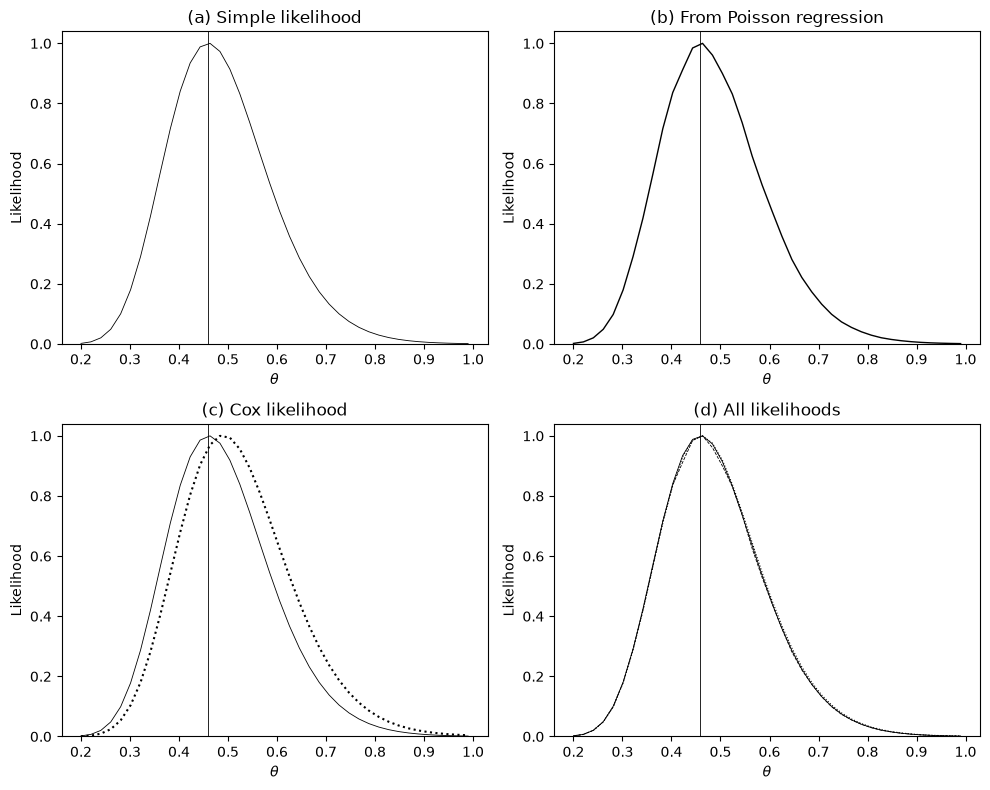

In [12]:
# reading data:
m1 = 10  # active
m2 = 12  # placebo
T12 = scan("epi.dat", skip=2, nlines=1)
T1 = T12[:10]
T2 = T12[10:22]
n12 = scan("epi.dat", skip=4, nlines=1)
n1 = n12[:10]
n2 = n12[10:22]
t1 = scan("epi.dat", skip=7, nlines=2)
t2 = scan("epi.dat", skip=10)

print("y_a and y_p = ", n1.sum(), n2.sum())
print("Sum T_i = ", T1.sum(), T2.sum())

npar = 40
theta = np.linspace(0.2, .99, npar)
loglik = 29 * np.log(97 * theta / (97 * theta + 109)) + 71 * np.log(109 / (97 * theta + 109))
like1 = np.exp(loglik - loglik.max())

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.ravel()

that = 29 / 97 / 71 * 109
ax = axes[0]
ax.plot(theta, like1, "k-", lw=0.6)
ax.axvline(that, color="k", lw=0.6)
ax.set_title("(a) Simple likelihood")

# .....................poisson regression:
y = np.concatenate([n1, n2])
x = np.concatenate([np.ones(m1), np.zeros(m2)])
off = np.log(np.concatenate([T1, T2]))

xreg = sm.GLM(y, sm.add_constant(x), offset=off, family=sm.families.Poisson()).fit()
print(xreg.summary(xname=["(Intercept)", "x"]))


def fun1(b0, b1):
    logmu = off + b0 + b1 * x
    return np.sum(-np.exp(logmu) + y * logmu)


bb0 = np.linspace(-.1, -.99, 20)
bb = np.log(theta)
loglik2 = np.array([[fun1(b0, b) for b in bb] for b0 in bb0])
loglik2 = loglik2.max(axis=0)  # profile over b0
like2 = np.exp(loglik2 - loglik2.max())

ax = axes[1]
ax.plot(theta, like2, "k-", lw=1.0)
ax.axvline(that, color="k", lw=0.6)
ax.set_title("(b) From Poisson regression")

# ......  Cox likelihood:
loglik3 = 29 * np.log(theta / (m1 * theta + m2)) + 71 * np.log(1 / (m1 * theta + m2))
like30 = np.exp(loglik3 - loglik3.max())

ax = axes[2]
ax.plot(theta, like30, "k:", lw=1.5)
ax.axvline(that, color="k", lw=0.6)
ax.set_title("(c) Cox likelihood")

# better computation:
cutp = np.arange(1, 15)
d1 = table(cut(T1, cutp - .01), len(cutp) - 1)
risk1 = np.concatenate([[m1], m1 - np.cumsum(d1)])
d2 = table(cut(T2, cutp - .1), len(cutp) - 1)
risk2 = np.concatenate([[m2], m2 - np.cumsum(d2)])
breaks = np.concatenate([[0], cutp])
a1 = table(cut(t1, breaks), len(breaks) - 1)
a2 = table(cut(t2, breaks), len(breaks) - 1)


def fun2(th):
    return np.sum(a1 * np.log(th / (risk1 * th + risk2))) + np.sum(a2 * np.log(1 / (risk1 * th + risk2)))


loglik3 = np.array([fun2(th) for th in theta])
like3 = np.exp(loglik3 - loglik3.max())
ax.plot(theta, like3, "k-", lw=0.6)

# all likelihoods:
ax = axes[3]
ax.plot(theta, like1, "k-", lw=0.6)
ax.plot(theta, like2, "k--", lw=0.6)
ax.plot(theta, like3, "k:", lw=0.8)
ax.axvline(that, color="k", lw=0.6)
ax.set_title("(d) All likelihoods")

for ax in axes:
    ax.set_ylim(0, 1.04)
    ax.set_xlabel(r"$\theta$")
    ax.set_ylabel("Likelihood")
fig.tight_layout()
plt.show()